# Miser pour le gain

## La question

Le document précédent demandait : peut-on **désigner le vainqueur** mieux que le favori ?
La réponse était à peu près non, et surtout : même quand on le trouve, **la mise perd de
l'argent**. Retrouver le cheval qui gagne n'est pas la même chose que rendre plus d'euros
qu'on en a misés.

Ici la question change. On cherche la règle de mise qui **maximise les gains**, pas celle
qui a le plus souvent raison. Le cheval intéressant n'est donc pas forcément le plus
performant. C'est celui dont **la cote paie plus que ses chances réelles**. Cet écart peut
se trouver sur un favori trop délaissé. Il peut aussi se trouver sur un outsider — un
cheval que le public néglige, et dont le prix est alors trop généreux.

Ce n'est pas un système de jeu. On mise **1 € au simple gagnant**, à plat, sur des courses
déjà courues, pour comparer des règles. Le prix retenu est la **cote au départ** : c'est
ce que le pari aurait rapporté s'il avait été tenu jusqu'au top. Les mouvements de cote
dans la journée, le placé et les paris combinés restent dehors.

La base consultée ne contient pas les vingt mois du panorama précédent. Elle couvre les
courses présentes au moment de la lecture — en pratique, **septembre 2026**, les arrivées
s'arrêtant avant les programmes encore à courir. Les dates exactes figurent dans le
premier tableau. La méthode, elle, est faite pour s'élargir : dès que l'historique couvre
plus d'une saison, l'apprentissage se fait sur 2025 et le jugement sur 2026.


## Sommaire

1. [Deux façons de juger une mise](#juger)
2. [Ce que rapporte vraiment chaque prix](#prix)
3. [Favori, deuxième prix, outsider](#regles)
4. [Choisir l'espérance plutôt que le vainqueur](#esperance)
5. [Passer son tour quand le prix n'est pas là](#passer)
6. [Ce qu'il ne faut pas conclure trop vite](#limites)
7. [Verdict](#verdict)


In [1]:
import sys
import warnings
from pathlib import Path

project_root = Path.cwd()
if not (project_root / "pmu").exists():
    project_root = project_root.parent
sys.path.append(str(project_root))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

import design_system as ds
from dataset.load_jeu_modelisation import load_jeu_modelisation
from pmu.types.types import ProgrammeIdentifier
from pmu.utils import programme_date_to_date

warnings.filterwarnings("ignore", category=FutureWarning)
THEME = ds.apply_theme("light")

start_date = ProgrammeIdentifier("01012025")
end_date = ProgrammeIdentifier("31122026")
debut = pd.Timestamp(programme_date_to_date(str(start_date)))
fin = pd.Timestamp(programme_date_to_date(str(end_date)))


In [2]:
ESPACE = "\u202f"


def nombre(valeur, decimales=0, unite=""):
    if pd.isna(valeur):
        return "—"
    texte = f"{valeur:,.{decimales}f}".replace(",", ESPACE).replace(".", ",")
    return f"{texte}{unite}"


def tableau(frame, titre=None, formats=None, barres=None, gradient=None, precision=0):
    styler = frame.style.set_table_styles(ds.table_css("light"))
    if titre:
        styler = styler.set_caption(titre)
    if formats:
        styler = styler.format(formats, na_rep="—")
    else:
        styler = styler.format(precision=precision, thousands=ESPACE, decimal=",", na_rep="—")
    if barres:
        styler = styler.bar(subset=barres, color=THEME["chart_3"], align="left", height=62, width=96)
    if gradient:
        styler = styler.background_gradient(
            cmap=ds.diverging_cmap("light"), subset=gradient, vmin=-1, vmax=1
        )
    return styler


def chiffres_cles(valeurs: dict, titre: str):
    frame = pd.DataFrame({"": list(valeurs.values())}, index=list(valeurs.keys()))
    return tableau(frame, titre, formats={"": "{}"})


def figure(titre: str, figsize=(11, 4.4)):
    fig, ax = plt.subplots(figsize=figsize)
    ax.set_title(titre)
    return fig, ax


def une_mise(frame, score, croissant=False):
    ordre = frame.assign(_score=np.asarray(score)).sort_values("_score", ascending=croissant)
    return ordre.groupby("course_id", observed=True).head(1)


def decrire(choix, nom, courses):
    pay = np.where(choix["gagnant"].to_numpy(), choix["cote_utile"].to_numpy(), 0.0)
    n = len(pay)
    if n == 0:
        return {
            "Règle": nom,
            "Paris": 0,
            "Courses jouées": 0.0,
            "Vainqueur trouvé": np.nan,
            "Euros rendus pour 1 €": np.nan,
            "Marge de hasard (±)": np.nan,
            "Cote médiane": np.nan,
            "Rang de prix médian": np.nan,
        }
    se = pay.std(ddof=1) / np.sqrt(n) if n > 1 else np.nan
    return {
        "Règle": nom,
        "Paris": n,
        "Courses jouées": n / courses,
        "Vainqueur trouvé": float(choix["gagnant"].mean()),
        "Euros rendus pour 1 €": float(pay.mean()),
        "Marge de hasard (±)": float(2 * se),
        "Cote médiane": float(choix["cote_utile"].median()),
        "Rang de prix médian": float(choix["rang_prix"].median()),
    }


FORMATS_REGLES = {
    "Paris": lambda v: nombre(v),
    "Courses jouées": lambda v: nombre(v * 100, 1, " %"),
    "Vainqueur trouvé": lambda v: nombre(v * 100, 1, " %"),
    "Euros rendus pour 1 €": lambda v: nombre(v, 3, " €"),
    "Marge de hasard (±)": lambda v: nombre(v, 3, " €"),
    "Cote médiane": lambda v: nombre(v, 1),
    "Rang de prix médian": lambda v: nombre(v, 1),
}


<a id="juger"></a>
## 1. Deux façons de juger une mise

Une règle peut être jugée de deux manières, et elles ne désignent pas le même cheval.

- **Trouver le vainqueur.** On compte les courses où le cheval choisi finit premier. Le favori
  gagne souvent : autour d'une course sur trois dans le document précédent. C'est flatteur,
  et insuffisant.
- **Rendre de l'argent.** On mise 1 €. Si le cheval gagne, on récupère sa cote. Sinon, on
  récupère 0. La moyenne de ces retours est le seul chiffre qui dit si la règle enrichit ou
  appauvrit. **1 € rendu signifie qu'on récupère sa mise. En dessous, on perd.**

Un exemple de principe, avant même les données. Un favori à cote 2 qui gagne une fois sur
trois rend \(0{,}33 \times 2 = 0{,}67\) €. Un outsider à cote 15 qui gagne une fois sur
vingt rend \(0{,}05 \times 15 = 0{,}75\) €. Le second a raison bien moins souvent, et
rend pourtant un peu plus. Le gain ne vient pas de la victoire : il vient du **prix**.

La cote annonce déjà une chance : un cheval à 5 est affiché à 1 chance sur 5. Cette annonce
est trop optimiste dans l'ensemble, parce que le prélèvement du PMU est dans le prix. Sur
une course, la somme des « 1 / cote » dépasse 1. Ce dépassement, c'est la marge du marché.
Pour gagner, il ne suffit pas d'être d'accord avec la cote. Il faut trouver un cheval dont
les chances réelles **dépassent** ce que sa cote paie.


In [3]:
brut = load_jeu_modelisation(start_date, end_date)
brut["gains_euros"] = brut["gains_carriere"] / 100
brut["taux_victoire"] = np.where(
    brut["nombre_courses"] > 0, brut["nombre_victoires"] / brut["nombre_courses"], np.nan
)
brut["taux_place"] = np.where(
    brut["nombre_courses"] > 0, brut["nombre_places"] / brut["nombre_courses"], np.nan
)
brut["log_gains"] = np.log10(brut["gains_euros"].clip(lower=1))
brut["cote_utile"] = brut["cote_directe"].where(brut["cote_directe"].between(1, 998))
brut["log_cote"] = np.log(brut["cote_utile"])
brut["gagnant"] = brut["ordre_arrivee"].eq(1)

courses_avec_vainqueur = brut.loc[brut["gagnant"], "course_id"].unique()
jeu = brut[brut["course_id"].isin(courses_avec_vainqueur)].copy()

prix = jeu.dropna(subset=["cote_utile", "taux_victoire", "taux_place", "age", "nombre_partants", "log_gains"]).copy()
encore_gagnee = prix.loc[prix["gagnant"], "course_id"].unique()
prix = prix[prix["course_id"].isin(encore_gagnee)].copy()
prix["place_corde_connue"] = prix["place_corde"].notna().astype(float)
prix["place_corde"] = prix["place_corde"].fillna(prix["nombre_partants"] / 2)
prix["log_partants"] = np.log(prix["nombre_partants"].clip(lower=1))
prix["rang_prix"] = prix.groupby("course_id")["cote_utile"].rank(method="first", ascending=True)
prix["chance_cote"] = 1 / prix["cote_utile"]

somme_chances = prix.groupby("course_id")["chance_cote"].sum()
premier = pd.to_datetime(prix["date_programme"]).min()
dernier = pd.to_datetime(prix["date_programme"]).max()
journees = pd.to_datetime(prix["date_programme"]).dt.normalize().nunique()
display(
    chiffres_cles(
        {
            "Première course utilisable": f"{premier:%d/%m/%Y}",
            "Dernière course utilisable": f"{dernier:%d/%m/%Y}",
            "Journées distinctes": nombre(journees),
            "Courses utilisables": nombre(prix["course_id"].nunique()),
            "Partants avec une cote": nombre(len(prix)),
            "Somme des chances affichées, médiane": nombre(somme_chances.median(), 2),
            "Courses où cette somme dépasse 1": f"{nombre((somme_chances > 1).mean() * 100, 1)} %",
        },
        "La marge déjà présente dans les cotes",
    )
)


,
Première course utilisable,09/09/2026
Dernière course utilisable,25/09/2026
Journées distinctes,3
Courses utilisables,127
Partants avec une cote,1 433
"Somme des chances affichées, médiane","1,15"
Courses où cette somme dépasse 1,"95,3 %"


**À retenir.** Sur ces courses, la somme des chances affichées vaut 1,15 en médiane, et elle
dépasse 1 dans 95 % des cas. Le marché ne propose pas un prix équitable : **une partie de
chaque euro misé est déjà prélevée**. Les dates extrêmes vont du 9 au 25 septembre 2026,
mais ce ne sont que **trois journées** de courses arrivées. Tout ce qui suit se lit à cette
échelle, pas à celle de vingt mois.


<a id="prix"></a>
## 2. Ce que rapporte vraiment chaque prix

Avant tout modèle, une question simple : **si l'on achète toujours le même genre de cote,
combien revient 1 € ?** Chaque partant est une mise d'1 €. S'il gagne, on encaisse sa cote.
On regroupe les chevaux par tranche de prix, du grand favori au très gros outsider.

La colonne « chances affichées » est la moyenne de 1 / cote dans la tranche. Si les chevaux
gagnaient aussi souvent que leur cote le dit, les euros rendus vaudraient 1. L'écart entre
le taux de victoire et ces chances dit si le prix était trop court ou trop généreux.


,Partants,Taux de victoire,Chances affichées,Euros rendus pour 1 €,Écart de chances
tranche,,,,,
1 à 2,20,"55,0 %","61,6 %","0,860 €","-6,6 points"
"2 à 3,5",85,"28,2 %","36,8 %","0,738 €","-8,5 points"
"3,5 à 6",161,"19,9 %","21,8 %","0,909 €","-2,0 points"
6 à 10,209,"13,4 %","13,1 %","1,055 €","0,3 points"
10 à 18,271,"7,0 %","7,7 %","0,860 €","-0,7 points"
18 à 40,323,"3,1 %","4,0 %","0,814 €","-0,9 points"
40 et plus,364,"0,8 %","1,3 %","0,544 €","-0,5 points"


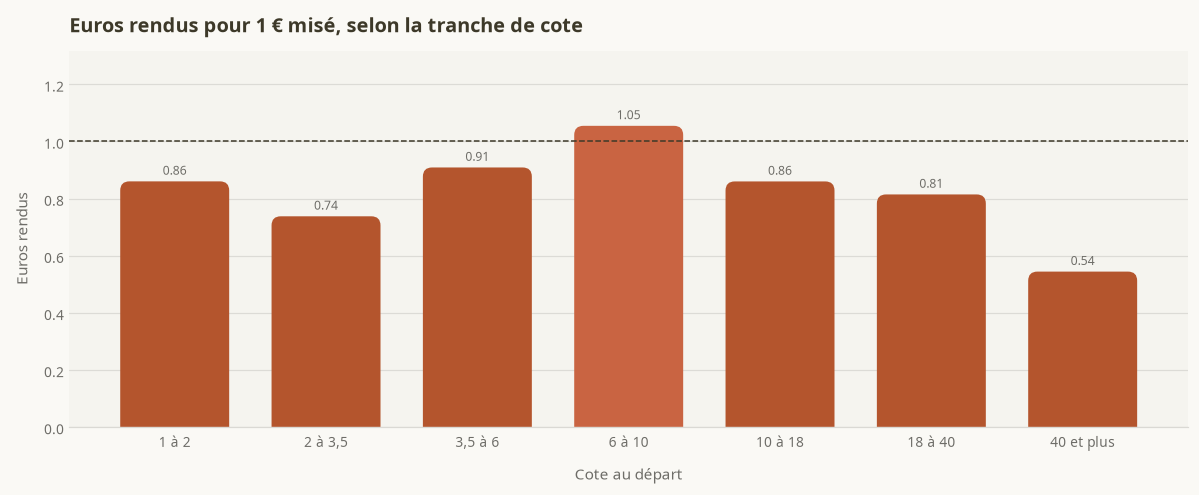

In [ ]:
bornes = [1, 2, 3.5, 6, 10, 18, 40, 1000]
etiquettes = ["1 à 2", "2 à 3,5", "3,5 à 6", "6 à 10", "10 à 18", "18 à 40", "40 et plus"]
prix["tranche"] = pd.cut(prix["cote_utile"], bornes, right=False, labels=etiquettes)
prix["retour"] = np.where(prix["gagnant"], prix["cote_utile"], 0.0)

par_prix = prix.groupby("tranche", observed=True).agg(
    partants=("cote_utile", "size"),
    taux=("gagnant", "mean"),
    chances=("chance_cote", "mean"),
    euros=("retour", "mean"),
)
par_prix = par_prix.rename(
    columns={
        "partants": "Partants",
        "taux": "Taux de victoire",
        "chances": "Chances affichées",
        "euros": "Euros rendus pour 1 €",
    }
)
par_prix["Écart de chances"] = par_prix["Taux de victoire"] - par_prix["Chances affichées"]

display(
    tableau(
        par_prix,
        "Un euro misé sur chaque partant, selon sa cote au départ",
        formats={
            "Partants": lambda v: nombre(v),
            "Taux de victoire": lambda v: nombre(v * 100, 1, " %"),
            "Chances affichées": lambda v: nombre(v * 100, 1, " %"),
            "Euros rendus pour 1 €": lambda v: nombre(v, 3, " €"),
            "Écart de chances": lambda v: nombre(v * 100, 1, " points"),
        },
    )
)

fig, ax = figure("Euros rendus pour 1 € misé, selon la tranche de cote", (11, 4.6))
valeurs = par_prix["Euros rendus pour 1 €"]
couleurs = [THEME["primary"] if v >= valeurs.max() - 1e-9 else THEME["chart_5"] for v in valeurs]
ax.bar(valeurs.index.astype(str), valeurs.to_numpy(), color=couleurs, width=0.72)
ax.axhline(1, color=THEME["foreground"], linewidth=1, linestyle="--")
ds.annotate_bars(ax, fmt="{:.2f}")
ds.rounded_bars(ax)
ax.set_ylabel("Euros rendus")
ax.set_xlabel("Cote au départ")
ax.set_ylim(0, max(1.15, float(valeurs.max()) * 1.25))
ax.tick_params(axis="x", labelrotation=0)
fig.tight_layout()


**À retenir.** Le très gros prix est le plus mauvais achat. Au-delà de 40, 1 € misé ne rend
que 0,54 €, et ces chevaux gagnent encore moins souvent que leur cote ne l'annonce. À
l'autre bout, le grand favori (cote 1 à 2) gagne souvent — 55 % — et perd quand même :
0,86 € rendus, parce que le prix est trop court. La tranche 6 à 10 est la seule à dépasser
1 € (1,06 €), d'un écart de chances de trois dixièmes de point. C'est trop mince pour y
voir une poche de value. Le fait utile est ailleurs : **la perte se concentre sur les prix
extrêmes, pas sur un cheval simplement « moins bien classé ».**


<a id="regles"></a>
## 3. Favori, deuxième prix, outsider

Les tranches mélangent des courses différentes. Ici on joue **un seul cheval par course**,
choisi uniquement d'après son prix.

Le rang 1 est le favori, le cheval à la cote la plus basse. Le rang 2 est le deuxième prix,
et ainsi de suite. « Le plus gros outsider » est le cheval à la cote la plus haute de la
course, quel que soit le nombre de partants.

La marge de hasard indique de combien le résultat pourrait encore bouger pour cette seule
raison : plus elle est large, moins un bon chiffre isolé est solide. Elle est grande quand
on gagne rarement et très gros.


,Paris,Courses jouées,Vainqueur trouvé,Euros rendus pour 1 €,Marge de hasard (±),Cote médiane,Rang de prix médian
Règle,,,,,,,
Rang 1 dans les prix,127,"100,0 %","27,6 %","0,713 €","0,228 €","3,0","1,0"
Rang 2 dans les prix,126,"99,2 %","19,0 %","0,794 €","0,309 €","4,7","2,0"
Rang 3 dans les prix,125,"98,4 %","14,4 %","0,903 €","0,410 €","6,6","3,0"
Rang 4 dans les prix,125,"98,4 %","13,6 %","1,179 €","0,544 €","9,3","4,0"
Rang 5 dans les prix,123,"96,9 %","6,5 %","0,611 €","0,429 €","12,0","5,0"
Rang 6 dans les prix,122,"96,1 %","7,4 %","0,965 €","0,656 €","15,0","6,0"
Le plus gros outsider,127,"100,0 %","1,6 %","0,402 €","0,772 €","90,0","11,0"


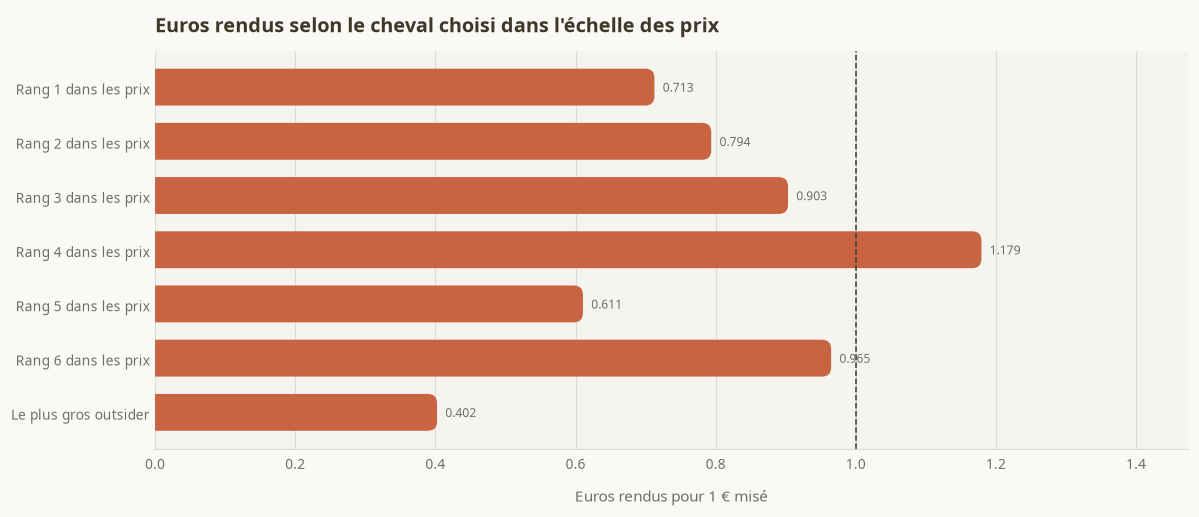

In [5]:
courses = prix["course_id"].nunique()
regles_prix = [decrire(prix[prix["rang_prix"] == rang], f"Rang {rang} dans les prix", courses) for rang in range(1, 7)]
outsider = prix.loc[prix.groupby("course_id")["rang_prix"].transform("max") == prix["rang_prix"]]
regles_prix.append(decrire(outsider, "Le plus gros outsider", courses))
bilan_prix = pd.DataFrame(regles_prix).set_index("Règle")
display(
    tableau(
        bilan_prix,
        "Une mise d'1 € par course, le cheval choisi d'après son seul prix",
        formats=FORMATS_REGLES,
    )
)

fig, ax = figure("Euros rendus selon le cheval choisi dans l'échelle des prix", (11, 4.8))
serie = bilan_prix["Euros rendus pour 1 €"]
ax.barh(serie.index.astype(str)[::-1], serie.to_numpy()[::-1], color=THEME["primary"], height=0.68)
ax.axvline(1, color=THEME["foreground"], linewidth=1, linestyle="--")
ds.annotate_bars(ax, orientation="horizontal", fmt="{:.3f}")
ds.rounded_bars(ax, orientation="horizontal")
ax.set_xlabel("Euros rendus pour 1 € misé")
ax.set_xlim(0, max(1.2, float(serie.max()) * 1.25))
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
fig.tight_layout()


**À retenir.** Prendre le plus gros outsider de chaque course rend 0,40 € pour 1 €, sur une
cote médiane de 90. C'est la pire règle du tableau, et même en ajoutant sa marge de hasard
on reste sous la mise. Le favori n'est pas le bon automatisme pour l'argent : il trouve le
vainqueur le plus souvent (28 %) et ne rend que 0,71 €. Du 2e au 4e prix, le rendement
affiché monte, jusqu'à 1,18 €, pendant que le taux de réussite baisse. Cette montée tient
dans le hasard : ±0,54 € au 4e prix, l'intervalle couvre aussi bien une perte franche qu'un
gain. On ne retient pas le 4e prix comme méthode. On retient qu'**allonger un peu le prix
n'est pas absurde, et que prendre le plus long l'est**.


<a id="esperance"></a>
## 4. Choisir l'espérance plutôt que le vainqueur

Une cote n'est intéressante que comparée à une chance. On estime donc, pour chaque cheval,
une probabilité de gagner **sans lui demander de battre le favori au classement**. Deux
estimations simples, apprises sur le passé et jugées sur des courses plus récentes :

- **Profil seul** : âge, palmarès, gains, corde, nombre de partants. La cote n'entre pas.
  Ce modèle peut contredire le marché, et donc désigner un cheval que le prix néglige.
- **Cote et profil** : les mêmes informations, plus la cote. Il colle au marché.

Les chances sont recollées à la réalité sur une période intermédiaire, pour qu'une
probabilité de 10 % veuille bien dire « gagne environ une fois sur dix ». Sans ce
recalage, un modèle gonfle les chances des chevaux rares et fabrique de fausses bonnes
affaires. Quand l'historique couvre plus d'une saison, cette période intermédiaire est
le second semestre 2025. Ici, l'historique est court : on coupe simplement le calendrier
en trois morceaux qui se suivent.


L'espérance d'une mise d'1 € est alors : **chances estimées × cote**. Au-dessus de 1, le
modèle juge que le prix paie trop. On compare deux gestes, uniquement sur les courses
tenues de côté pour le jugement :

- jouer le cheval **le plus probable** de la course (la chasse au vainqueur) ;
- jouer le cheval à **l'espérance la plus haute** (la chasse au prix).

Le second geste peut choisir un outsider. Il le fait quand le modèle lui donne plus de
chances que sa cote, pas parce que sa cote est haute.


In [6]:
PROFIL = [
    "age",
    "taux_victoire",
    "taux_place",
    "log_gains",
    "nombre_courses",
    "place_corde",
    "place_corde_connue",
    "log_partants",
]
AVEC_COTE = ["log_cote"] + PROFIL

jours = (
    pd.Series(pd.to_datetime(prix["date_programme"]).dt.normalize().unique())
    .sort_values()
    .reset_index(drop=True)
)
span = (jours.iloc[-1] - jours.iloc[0]).days
dates = pd.to_datetime(prix["date_programme"])
if span >= 180 and (dates < "2025-07-01").any() and (dates >= "2026-01-01").any():
    masque_app = dates < "2025-07-01"
    masque_cal = (dates >= "2025-07-01") & (dates < "2026-01-01")
    masque_test = dates >= "2026-01-01"
else:
    coupe_calage = max(1, int(len(jours) * 0.55))
    coupe_test = min(max(coupe_calage + 1, int(len(jours) * 0.75)), len(jours) - 1)
    borne_calage = jours.iloc[coupe_calage]
    borne_test = jours.iloc[coupe_test]
    masque_app = dates < borne_calage
    masque_cal = (dates >= borne_calage) & (dates < borne_test)
    masque_test = dates >= borne_test

apprentissage = prix.loc[masque_app]
calage = prix.loc[masque_cal]
test = prix.loc[masque_test].copy()


def chances_recales(colonnes):
    pipeline = Pipeline(
        [
            ("echelle", StandardScaler()),
            ("modele", LogisticRegression(max_iter=500)),
        ]
    )
    pipeline.fit(apprentissage[colonnes], apprentissage["gagnant"].astype(int))
    brut_calage = pipeline.predict_proba(calage[colonnes])[:, 1]
    brut_test = pipeline.predict_proba(test[colonnes])[:, 1]
    recalage = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1)
    recalage.fit(brut_calage, calage["gagnant"].astype(int))
    return pd.Series(recalage.predict(brut_test), index=test.index)


test["p_profil"] = chances_recales(PROFIL)
test["p_plein"] = chances_recales(AVEC_COTE)
test["ev_profil"] = test["p_profil"] * test["cote_utile"]
test["ev_plein"] = test["p_plein"] * test["cote_utile"]

display(
    chiffres_cles(
        {
            "Apprentissage": f"{pd.to_datetime(apprentissage['date_programme']).min():%d/%m/%Y} → {pd.to_datetime(apprentissage['date_programme']).max():%d/%m/%Y}",
            "Recalage des chances": f"{pd.to_datetime(calage['date_programme']).min():%d/%m/%Y} → {pd.to_datetime(calage['date_programme']).max():%d/%m/%Y}",
            "Jugement": f"{pd.to_datetime(test['date_programme']).min():%d/%m/%Y} → {pd.to_datetime(test['date_programme']).max():%d/%m/%Y}",
            "Courses d'apprentissage": nombre(apprentissage["course_id"].nunique()),
            "Courses de recalage": nombre(calage["course_id"].nunique()),
            "Courses de jugement": nombre(test["course_id"].nunique()),
            "Partants jugés": nombre(len(test)),
        },
        "Trois périodes successives, pour ne pas juger le modèle sur ce qu'il a déjà vu",
    )
)


,
Apprentissage,09/09/2026 → 09/09/2026
Recalage des chances,23/09/2026 → 23/09/2026
Jugement,25/09/2026 → 25/09/2026
Courses d'apprentissage,44
Courses de recalage,43
Courses de jugement,40
Partants jugés,444


In [7]:
test["tranche"] = pd.cut(test["cote_utile"], bornes, right=False, labels=etiquettes)
lecture = test.groupby("tranche", observed=True).agg(
    partants=("cote_utile", "size"),
    gagne=("gagnant", "mean"),
    cote=("chance_cote", "mean"),
    profil=("p_profil", "mean"),
    euros=("retour", "mean"),
    esperance=("ev_profil", "mean"),
)
lecture = lecture.rename(
    columns={
        "partants": "Partants",
        "gagne": "A vraiment gagné",
        "cote": "Chances de la cote",
        "profil": "Chances du profil",
        "euros": "Euros rendus pour 1 €",
        "esperance": "Espérance selon le profil",
    }
)
display(
    tableau(
        lecture,
        "Sur la période de jugement, les chances du profil comparées à celles de la cote",
        formats={
            "Partants": lambda v: nombre(v),
            "A vraiment gagné": lambda v: nombre(v * 100, 1, " %"),
            "Chances de la cote": lambda v: nombre(v * 100, 1, " %"),
            "Chances du profil": lambda v: nombre(v * 100, 1, " %"),
            "Euros rendus pour 1 €": lambda v: nombre(v, 3, " €"),
            "Espérance selon le profil": lambda v: nombre(v, 2, " €"),
        },
    )
)


,Partants,A vraiment gagné,Chances de la cote,Chances du profil,Euros rendus pour 1 €,Espérance selon le profil
tranche,,,,,,
1 à 2,9,"55,6 %","59,6 %","14,1 %","0,878 €","0,23 €"
"2 à 3,5",30,"36,7 %","36,8 %","16,4 %","0,993 €","0,45 €"
"3,5 à 6",48,"14,6 %","22,3 %","11,9 %","0,654 €","0,54 €"
6 à 10,53,"9,4 %","13,5 %","12,3 %","0,713 €","0,92 €"
10 à 18,78,"7,7 %","7,7 %","9,8 %","0,949 €","1,29 €"
18 à 40,100,"5,0 %","4,0 %","8,4 %","1,390 €","2,18 €"
40 et plus,126,"0,8 %","1,3 %","6,8 %","0,468 €","6,73 €"


In [8]:
n_test = test["course_id"].nunique()
favori = une_mise(test, test["cote_utile"], croissant=True)
gros = une_mise(test, test["cote_utile"], croissant=False)
lignes = [
    decrire(favori, "Favori (plus basse cote)", n_test),
    decrire(gros, "Plus gros outsider", n_test),
    decrire(une_mise(test, test["p_profil"]), "Plus probable — profil seul", n_test),
    decrire(une_mise(test, test["ev_profil"]), "Plus forte espérance — profil seul", n_test),
    decrire(une_mise(test, test["p_plein"]), "Plus probable — cote et profil", n_test),
    decrire(une_mise(test, test["ev_plein"]), "Plus forte espérance — cote et profil", n_test),
]
bilan_modeles = pd.DataFrame(lignes).set_index("Règle")
display(
    tableau(
        bilan_modeles,
        "Chasser le vainqueur, ou chasser le prix — courses non vues à l'apprentissage",
        formats=FORMATS_REGLES,
    )
)


,Paris,Courses jouées,Vainqueur trouvé,Euros rendus pour 1 €,Marge de hasard (±),Cote médiane,Rang de prix médian
Règle,,,,,,,
Favori (plus basse cote),40,"100,0 %","27,5 %","0,662 €","0,381 €","2,8","1,0"
Plus gros outsider,40,"100,0 %","0,0 %","0,000 €","0,000 €","108,0","11,5"
Plus probable — profil seul,40,"100,0 %","15,0 %","0,767 €","0,736 €","9,1","4,0"
Plus forte espérance — profil seul,40,"100,0 %","0,0 %","0,000 €","0,000 €","78,0","10,5"
Plus probable — cote et profil,40,"100,0 %","40,0 %","1,018 €","0,445 €","3,0","1,0"
Plus forte espérance — cote et profil,40,"100,0 %","7,5 %","0,775 €","0,876 €","11,0","4,0"


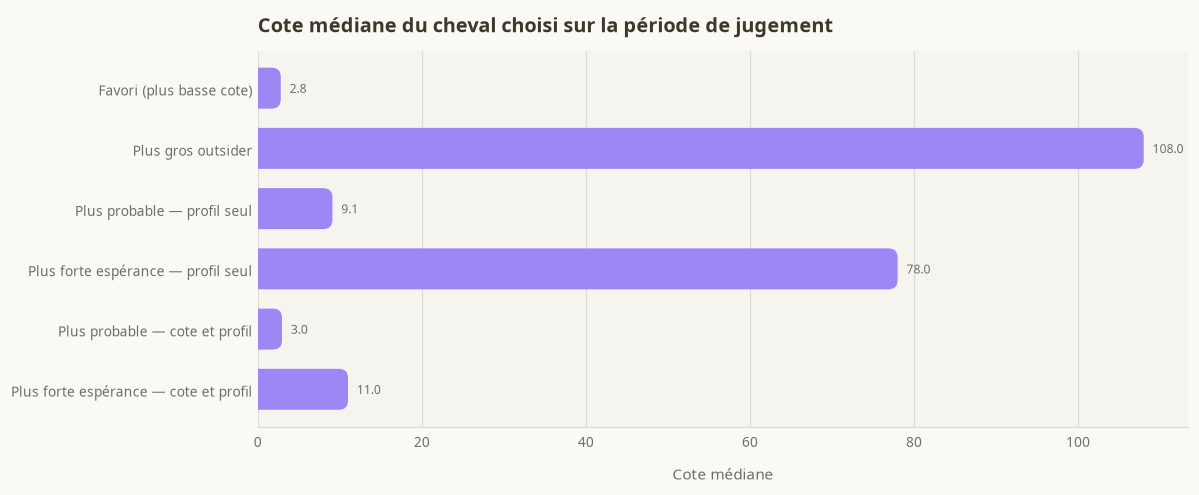

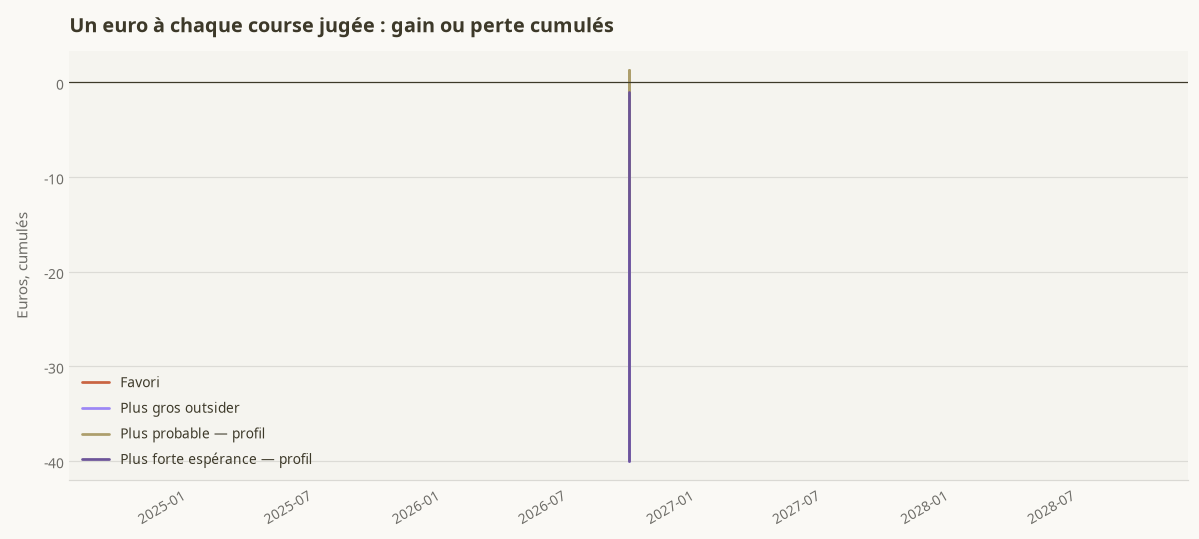

In [9]:
fig, ax = figure("Cote médiane du cheval choisi sur la période de jugement", (11, 4.6))
cotes = bilan_modeles["Cote médiane"]
ax.barh(cotes.index.astype(str)[::-1], cotes.to_numpy()[::-1], color=THEME["chart_2"], height=0.68)
ds.annotate_bars(ax, orientation="horizontal", fmt="{:.1f}")
ds.rounded_bars(ax, orientation="horizontal")
ax.set_xlabel("Cote médiane")
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
fig.tight_layout()


def cumul(choix):
    classe = choix.sort_values(["date_programme", "course_id"])
    flux = np.where(classe["gagnant"].to_numpy(), classe["cote_utile"].to_numpy() - 1.0, -1.0)
    return classe["date_programme"], np.cumsum(flux)


fig, ax = figure("Un euro à chaque course jugée : gain ou perte cumulés", (11, 5))
traces = [
    ("Favori", favori),
    ("Plus gros outsider", gros),
    ("Plus probable — profil", une_mise(test, test["p_profil"])),
    ("Plus forte espérance — profil", une_mise(test, test["ev_profil"])),
]
for nom, choix in traces:
    dates, courbe = cumul(choix)
    ax.plot(dates, courbe, linewidth=1.8, label=nom)
ax.axhline(0, color=THEME["foreground"], linewidth=0.8)
ax.set_ylabel("Euros, cumulés")
ax.legend(frameon=False)
fig.autofmt_xdate()
fig.tight_layout()


**À retenir.** Le profil seul ne baisse pas assez vite quand le prix s'allonge. Sur la
journée de jugement, il prête encore environ 7 % de chances aux chevaux à plus de 40, qui
en gagnent moins de 1 %. Multipliée par une cote de 70 ou 80, cette chance fabrique une
espérance très au-dessus de 1 €. La règle « plus forte espérance » choisit alors **le même
genre de cheval que le plus gros outsider** : cote médiane 78, rang 10 ou 11, aucun
vainqueur, 0 € rendu. Ce n'est pas une affaire détectée. C'est la formule qui, faute d'une
chance bien calibrée, retombe sur le prix le plus haut.

Le modèle qui voit la cote reste près du favori quand on lui demande le cheval le plus
probable : cote médiane 3, 40 % de vainqueurs, 1,02 € rendus. Le chiffre dépasse la mise,
et la marge de hasard est de ±0,45 € sur 40 courses d'une seule journée. Le hasard couvre
aussi bien un gain qu'une perte. Lui demander l'espérance plutôt que la probabilité allonge
la cote (médiane 11, rang 4) et ramène le retour à 0,78 €.


<a id="passer"></a>
## 5. Passer son tour quand le prix n'est pas là

Jusqu'ici, chaque course reçoit une mise. C'est une contrainte dure : même quand aucun
cheval n'a d'espérance au-dessus de 1, on joue quand même le moins mauvais. Un parieur qui
cherche un prix peut **ne pas jouer**.

On reprend l'espérance du profil seul — le seul modèle capable de contredire la cote — et
l'on ne mise que si le meilleur cheval de la course dépasse un seuil. 1,00 veut dire
« le modèle voit au moins le retour de la mise ». 1,20 veut dire « il exige 20 centimes
d'avance avant de sortir 1 € ». Les seuils ne sont pas choisis parce que l'un d'eux gagne :
on les affiche tous, pour voir si la sélection change la nature du résultat. Un seuil qui
ne joue presque plus n'est pas une découverte, c'est un échantillon trop mince.


,Paris,Courses jouées,Vainqueur trouvé,Euros rendus pour 1 €,Marge de hasard (±),Cote médiane,Rang de prix médian
Règle,,,,,,,
"Espérance d'au moins 1,00",39,"97,5 %","0,0 %","0,000 €","0,000 €","75,0","10,0"
"Espérance d'au moins 1,05",39,"97,5 %","0,0 %","0,000 €","0,000 €","75,0","10,0"
"Espérance d'au moins 1,10",39,"97,5 %","0,0 %","0,000 €","0,000 €","75,0","10,0"
"Espérance d'au moins 1,20",39,"97,5 %","0,0 %","0,000 €","0,000 €","75,0","10,0"
"Espérance d'au moins 1,40",39,"97,5 %","0,0 %","0,000 €","0,000 €","75,0","10,0"


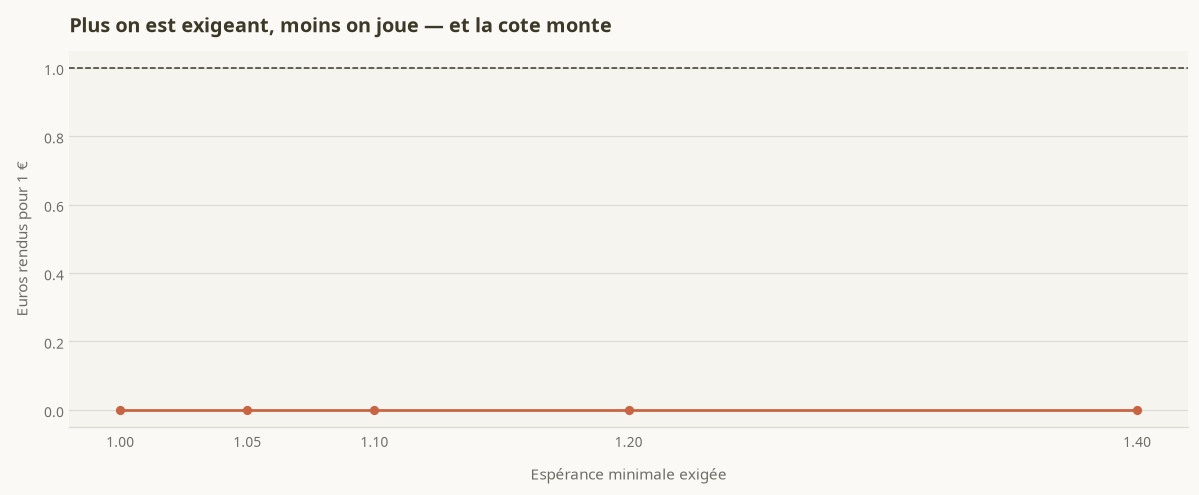

In [10]:
seuils = [1.0, 1.05, 1.1, 1.2, 1.4]
selectif = []
for seuil in seuils:
    meilleur = une_mise(test, test["ev_profil"])
    retenu = meilleur[meilleur["_score"] >= seuil]
    selectif.append(decrire(retenu, f"Espérance d'au moins {seuil:.2f}".replace(".", ","), n_test))
bilan_seuils = pd.DataFrame(selectif).set_index("Règle")
display(
    tableau(
        bilan_seuils,
        "Ne jouer que si le profil voit un prix trop généreux",
        formats=FORMATS_REGLES,
    )
)

fig, ax = figure("Plus on est exigeant, moins on joue — et la cote monte", (11, 4.6))
ax.plot(
    [1.0, 1.05, 1.1, 1.2, 1.4],
    bilan_seuils["Euros rendus pour 1 €"],
    color=THEME["primary"],
    marker="o",
    linewidth=1.8,
    label="Euros rendus pour 1 €",
)
ax.axhline(1, color=THEME["foreground"], linewidth=1, linestyle="--")
ax.set_xlabel("Espérance minimale exigée")
ax.set_ylabel("Euros rendus pour 1 €")
ax.set_xticks([1.0, 1.05, 1.1, 1.2, 1.4])
fig.tight_layout()


**À retenir.** Monter le seuil ne change rien. 39 courses sur 40 ont déjà un cheval dont
l'espérance dépasse 1,40, parce que le profil surévalue les outsiders. On joue presque
toutes les courses, toujours autour d'une cote 75, et l'on ne touche aucun vainqueur.
L'exigence ne filtre que si les chances estimées sont assez basses pour que la plupart des
chevaux restent sous 1. Ici, elles ne le sont pas : **le seuil ne crée pas un prix, il
laisse passer le plus long.**


<a id="limites"></a>
## 6. Ce qu'il ne faut pas conclure trop vite


In [11]:
limites = pd.DataFrame(
    [
        (
            "La cote au départ est un prix de dernière minute",
            "Elle sert ici de prix encaissé. Un avis donné le matin ne pourrait pas s'en servir : seule la cote de la veille serait honnête, et elle est moins précise.",
        ),
        (
            "Un euro à plat n'est pas une gestion de mise",
            "On ne met pas plus d'argent sur les écarts les plus grands. Une mise proportionnelle à l'écart changerait les montants, pas le fait qu'un prix soit bon ou mauvais.",
        ),
        (
            "L'outsider gagnant pèse très lourd",
            "Une cote à 40 qui tombe une fois déplace le cumul de 40 €. La marge de hasard sert à ne pas prendre ce coup pour une méthode.",
        ),
        (
            "Le modèle est volontairement simple",
            "Il ignore le driver, l'entraîneur, la musique récente calculée sans regarder le futur, et les mouvements d'argent. Un écart de prix, s'il existe, est peut-être là — pas dans la cote elle-même.",
        ),
        (
            "Les chevaux reviennent",
            "Le même nom court des dizaines de fois. Une partie de ce que le modèle « sait » est une mémoire des habitués, pas une lecture de la course du jour.",
        ),
        (
            "Le placé et les combinés sont un autre jeu",
            "Un outsider peut être une mauvaise affaire au gagnant et une autre question au couplé. Ce document ne tranche que le simple gagnant.",
        ),
    ],
    columns=["Point de vigilance", "Pourquoi ça compte"],
).set_index("Point de vigilance")
display(
    tableau(
        limites,
        "Avant de parler d'une chasse aux outsiders",
        formats={"Pourquoi ça compte": "{}"},
    )
)


,Pourquoi ça compte
Point de vigilance,
La cote au départ est un prix de dernière minute,"Elle sert ici de prix encaissé. Un avis donné le matin ne pourrait pas s'en servir : seule la cote de la veille serait honnête, et elle est moins précise."
Un euro à plat n'est pas une gestion de mise,"On ne met pas plus d'argent sur les écarts les plus grands. Une mise proportionnelle à l'écart changerait les montants, pas le fait qu'un prix soit bon ou mauvais."
L'outsider gagnant pèse très lourd,Une cote à 40 qui tombe une fois déplace le cumul de 40 €. La marge de hasard sert à ne pas prendre ce coup pour une méthode.
Le modèle est volontairement simple,"Il ignore le driver, l'entraîneur, la musique récente calculée sans regarder le futur, et les mouvements d'argent. Un écart de prix, s'il existe, est peut-être là — pas dans la cote elle-même."
Les chevaux reviennent,"Le même nom court des dizaines de fois. Une partie de ce que le modèle « sait » est une mémoire des habitués, pas une lecture de la course du jour."
Le placé et les combinés sont un autre jeu,Un outsider peut être une mauvaise affaire au gagnant et une autre question au couplé. Ce document ne tranche que le simple gagnant.


**À retenir.** Rien de tout cela n'interdit de chercher un prix mal ajusté. Cela interdit
de confondre une cote élevée avec une bonne affaire, et un beau cumul sur peu de courses
avec une méthode.


<a id="verdict"></a>
## 7. Verdict


In [12]:
verdict = pd.DataFrame(
    [
        (
            "Juger une règle au nombre de vainqueurs",
            "Utile pour classer",
            "Le favori trouve le vainqueur dans 28 % des courses et ne rend que 0,71 €. Le taux de réussite et l'argent rendu ne désignent pas la même règle.",
        ),
        (
            "Jouer le plus gros outsider",
            "Non",
            "0,40 € rendus, cote médiane 90, 1,6 % de vainqueurs. Le prix le plus haut est le plus mauvais achat de ce tableau, pas une affaire.",
        ),
        (
            "Descendre de quelques rangs sous le favori",
            "Pas établi",
            "Le rendement affiché monte jusqu'au 4e prix (1,18 €), puis retombe. La marge de hasard (±0,54 €) avale ce dépassement. Ce n'est pas une règle, c'est une piste à revérifier sur plus de journées.",
        ),
        (
            "Choisir l'espérance plutôt que la probabilité",
            "Le bon geste, à condition que la chance soit juste",
            "Sans la cote, l'espérance désigne l'outsider et rend 0 € sur la journée de jugement. Avec la cote, elle allonge le prix (médiane 11) et rend 0,78 €. La formule ne vaut que si les chances baissent au moins aussi vite que 1 / cote.",
        ),
        (
            "Ne jouer que les écarts les plus nets",
            "Sans effet ici",
            "Presque toutes les courses dépassent déjà le seuil le plus haut, parce que les outsiders sont surévalués par le profil. On ne joue pas moins : on joue toujours trop long.",
        ),
    ],
    columns=["Question", "Réponse", "Lecture"],
).set_index("Question")
display(
    tableau(
        verdict,
        "Ce que l'on peut retenir pour la suite",
        formats={"Réponse": "{}", "Lecture": "{}"},
    )
)


,Réponse,Lecture
Question,,
Juger une règle au nombre de vainqueurs,Utile pour classer,"Le favori trouve le vainqueur dans 28 % des courses et ne rend que 0,71 €. Le taux de réussite et l'argent rendu ne désignent pas la même règle."
Jouer le plus gros outsider,Non,"0,40 € rendus, cote médiane 90, 1,6 % de vainqueurs. Le prix le plus haut est le plus mauvais achat de ce tableau, pas une affaire."
Descendre de quelques rangs sous le favori,Pas établi,"Le rendement affiché monte jusqu'au 4e prix (1,18 €), puis retombe. La marge de hasard (±0,54 €) avale ce dépassement. Ce n'est pas une règle, c'est une piste à revérifier sur plus de journées."
Choisir l'espérance plutôt que la probabilité,"Le bon geste, à condition que la chance soit juste","Sans la cote, l'espérance désigne l'outsider et rend 0 € sur la journée de jugement. Avec la cote, elle allonge le prix (médiane 11) et rend 0,78 €. La formule ne vaut que si les chances baissent au moins aussi vite que 1 / cote."
Ne jouer que les écarts les plus nets,Sans effet ici,"Presque toutes les courses dépassent déjà le seuil le plus haut, parce que les outsiders sont surévalués par le profil. On ne joue pas moins : on joue toujours trop long."


L'objectif n'était pas de couronner un modèle. Sur ces trois journées, **aucune règle ne
maximise les gains au point d'en faire une méthode**. Le favori gagne le plus souvent et
perd de l'argent. L'outsider automatique en perd davantage. Le 4e prix affiche un retour
au-dessus de la mise, à l'intérieur d'une marge de hasard trop large pour qu'on s'y fie.

Maximiser les gains change toutefois le cheval qu'on cherche : on ne lui demande plus
d'être le plus probable, on lui demande d'être **sous-payé**. Encore faut-il que la chance
qu'on lui prête descende quand la cote monte. Si elle descend trop lentement, l'espérance
désigne toujours le plus gros prix — et l'on a recréé, avec une formule, la pire des règles
mécaniques.

La piste utile n'est donc pas « jouer plus long ». C'est une chance estimée qui contredit
vraiment la cote, puis une mise seulement là où cette contradiction tient. Avec 127 courses
arrivées, le document montre le geste. Il ne mesure pas encore l'écart.
